In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import KFold

In [2]:
# Loading the dataset
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
print(df.shape)
print(df.columns)
print(df.dtypes)

(5000, 9)
Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')
lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


In [4]:
# Calculate the percentage of missing values in each column
df.isnull().mean() * 100

lead_source                 2.96
industry                    4.80
employment_status           3.88
location                    4.16
annual_income               7.38
number_of_courses_viewed    0.00
interaction_count           0.00
lead_score                  0.70
converted                   0.00
dtype: float64

In [5]:
# Categorical columns
categorical = ['lead_source','industry','employment_status','location']

# Numerical columns
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

# Target variable
target = 'converted'

# Replace missing values in categorical columns with 'NA'
df[categorical] = df[categorical].fillna('NA')

# Replacing missing values in numerical columns with 0.0
df[numerical] = df[numerical].fillna(0.0)

# Checking that there are no missing values left
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [6]:
# Splitting off 20% for the test dataset
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# Splitting the remaining data into training and validation sets
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Displaying the sizes of the three datasets
print("Training:", len(df_train))
print("Validation:", len(df_val))
print("Test:", len(df_test))

Training: 3000
Validation: 1000
Test: 1000


In [7]:
# Separating the target variable from the training features
y_train = df_train[target]
X_train = df_train.drop(columns=[target])

# Separating the target variable from the validation features
y_val = df_val[target]
X_val = df_val.drop(columns=[target])

## Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
- Use the training dataset for that
  
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- lead_score
- number_of_courses_viewed
- interaction_count
- annual_income

In [8]:
# Test each numerical feature using the training dataset
for column in numerical:

    # Calculate AUC using the feature as the prediction score
    auc = roc_auc_score(y_train, X_train[column])

    # If AUC is below 0.5, reverse the direction
    if auc < 0.5: auc = roc_auc_score(y_train, -X_train[column])

    # Print the feature and its AUC
    print(column, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


## Question 2: Training the model
Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

`LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`

What's the AUC of this model on the validation dataset? (round to 3 digits)

In [9]:
# Convert the training features into dictionaries
train_dict = X_train.to_dict(orient='records')

# Convert the validation features into dictionaries
val_dict = X_val.to_dict(orient='records')

# Create the encoder
dv = DictVectorizer(sparse=False)

# Learn the feature mapping from training data
X_train_encoded = dv.fit_transform(train_dict)

# Apply the same mapping to validation data
X_val_encoded = dv.transform(val_dict)

In [10]:
# Create the model with the specified parameters
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

# Train the model
model.fit(X_train_encoded, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


In [11]:
# Get the probability that each validation lead converts
y_pred_proba = model.predict_proba(X_val_encoded)[:, 1]

# Calculate the validation ROC AUC
auc = roc_auc_score(y_val, y_pred_proba)

# Round the result to 3 decimal places
print(round(auc, 3))

0.732


## Question 3: Precision and Recall
Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them
  
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

In [12]:
# Create thresholds from 0.00 to 1.00, with a step of 0.01
thresholds = np.arange(0.0, 1.01, 0.01)

# Lists to store the results
precisions = []
recalls = []

# Test every threshold
for threshold in thresholds:

    # Convert probabilities into 0/1 predictions
    y_pred = (y_pred_proba >= threshold).astype(int)

    # Calculate precision; use 0 if precision is undefined
    precision = precision_score(y_val, y_pred, zero_division=0)

    # Calculate recall; use 0 if recall is undefined
    recall = recall_score(y_val, y_pred, zero_division=0)

    # Save the results
    precisions.append(precision)
    recalls.append(recall)

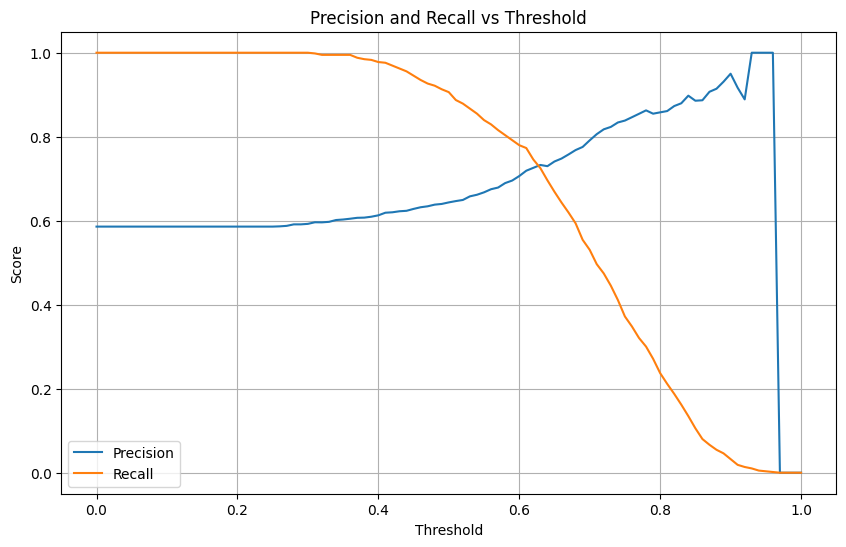

In [13]:
# Plot precision and recall against the thresholds
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)

plt.show()

Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

  $$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

Where 
P is precision and R is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

In [14]:
# Find the threshold where precision and recall are closest
best_threshold = None
smallest_difference = float('inf')

for i, threshold in enumerate(thresholds):

    precision = precisions[i]
    recall = recalls[i]

    # Ignore thresholds where both metrics are zero
    if precision == 0 and recall == 0:
        continue

    # Calculate the absolute difference
    difference = abs(precision - recall)

    # Keep the threshold with the smallest difference
    if difference < smallest_difference:
        smallest_difference = difference
        best_threshold = threshold

print("Best threshold:", round(best_threshold, 2))
print("Smallest difference:", round(smallest_difference, 4))

Best threshold: 0.63
Smallest difference: 0.0075


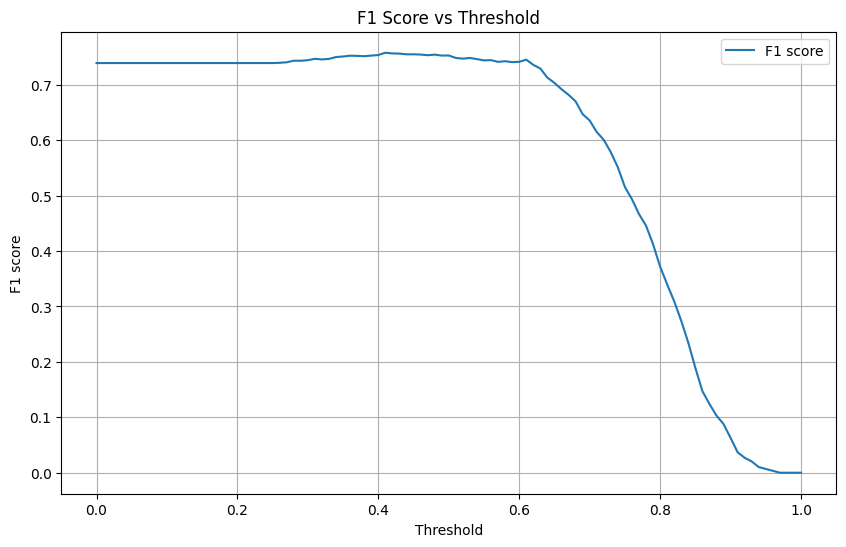

Best threshold: 0.41
Highest F1 score: 0.758


In [15]:
# Create a list to store F1 scores
f1_scores = []

# Calculate F1 for each threshold
for i in range(len(thresholds)):

    # Get precision and recall for this threshold
    precision = precisions[i]
    recall = recalls[i]

    # Avoid division by zero
    if precision + recall == 0:
        f1 = 0
    else:
        # Calculate the F1 score
        f1 = 2 * precision * recall / (precision + recall)

    # Save the F1 score
    f1_scores.append(f1)

# Plot F1 scores against thresholds
plt.figure(figsize=(10, 6))

plt.plot(thresholds, f1_scores, label='F1 score')

plt.xlabel('Threshold')
plt.ylabel('F1 score')
plt.title('F1 Score vs Threshold')
plt.legend()
plt.grid(True)

plt.show()

# Find the index of the highest F1 score
best_index = np.argmax(f1_scores)

# Get the threshold and F1 score at that index
best_f1_threshold = thresholds[best_index]
best_f1_score = f1_scores[best_index]

print("Best threshold:", round(best_f1_threshold, 2))
print("Highest F1 score:", round(best_f1_score, 3))

## Question 5: 5-Fold CV
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

`KFold(n_splits=5, shuffle=True, random_state=1)`

- Iterate over different folds of `df_full_train`
- Split the data into train and validation
- Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
- Use AUC to evaluate the model on validation
- 
How large is standard deviation of the scores across different folds?

In [16]:
# Create five folds with shuffling
kf = KFold(n_splits=5, shuffle=True, random_state=1)

# Store the AUC score from each fold
scores = []

# Iterate through the five folds
for train_idx, val_idx in kf.split(df_full_train):

    # Select the training and validation rows for this fold
    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]

    # Separate the target from the features
    y_fold_train = df_fold_train['converted']
    y_fold_val = df_fold_val['converted']

    X_fold_train = df_fold_train.drop(columns=['converted'])
    X_fold_val = df_fold_val.drop(columns=['converted'])

    # Convert features into dictionaries
    train_dict = X_fold_train.to_dict(orient='records')
    val_dict = X_fold_val.to_dict(orient='records')

    # Encode using training data only
    dv_fold = DictVectorizer(sparse=False)
    X_fold_train_encoded = dv_fold.fit_transform(train_dict)
    X_fold_val_encoded = dv_fold.transform(val_dict)

    # Create and train the model
    model_fold = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

    model_fold.fit(X_fold_train_encoded, y_fold_train)

    # Predict conversion probabilities
    y_fold_pred_proba = model_fold.predict_proba(X_fold_val_encoded)[:, 1]

    # Calculate and save this fold's AUC
    auc_fold = roc_auc_score(y_fold_val, y_fold_pred_proba)
    scores.append(auc_fold)

    print("Fold AUC:", round(auc_fold, 3))

# Calculate the mean and standard deviation of the five AUC scores
print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3))

Fold AUC: 0.731
Fold AUC: 0.73
Fold AUC: 0.736
Fold AUC: 0.741
Fold AUC: 0.721
Mean AUC: 0.732
Standard deviation: 0.007


## Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter C

- Iterate over the following `C` values: `[0.000001, 0.001, 1]`
- Initialize `KFold` with the same parameters as previously
- Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
  
Which `C` leads to the best mean ROC AUC?

In [17]:
# C values to try
C_values = [0.000001, 0.001, 1]

# Store the mean and std of the AUC for each C
results = []

for C in C_values:

    # Same KFold settings as in Question 5
    kf = KFold(n_splits=5, shuffle=True, random_state=1)

    # Store the AUC score from each fold for this C
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):

        # Select the training and validation rows for this fold
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        # Separate the target from the features
        y_fold_train = df_fold_train[target]
        y_fold_val = df_fold_val[target]

        X_fold_train = df_fold_train.drop(columns=[target])
        X_fold_val = df_fold_val.drop(columns=[target])

        # Encode using training data only
        dv_fold = DictVectorizer(sparse=False)
        X_fold_train_encoded = dv_fold.fit_transform(X_fold_train.to_dict(orient='records'))
        X_fold_val_encoded = dv_fold.transform(X_fold_val.to_dict(orient='records'))

        # Train the model with this value of C
        model_fold = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model_fold.fit(X_fold_train_encoded, y_fold_train)

        # Predict probabilities and calculate this fold's AUC
        y_fold_pred_proba = model_fold.predict_proba(X_fold_val_encoded)[:, 1]
        scores.append(roc_auc_score(y_fold_val, y_fold_pred_proba))

    # Save the mean and std for this C
    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)
    results.append((C, mean_auc, std_auc))

    print("C =", C, "| Mean AUC:", mean_auc, "| Std:", std_auc)

# Pick the best C: highest mean, then lowest std, then smallest C
best = sorted(results, key=lambda r: (-r[1], r[2], r[0]))[0]
print("Best C:", best[0])

C = 1e-06 | Mean AUC: 0.617 | Std: 0.019
C = 0.001 | Mean AUC: 0.749 | Std: 0.01
C = 1 | Mean AUC: 0.732 | Std: 0.007
Best C: 0.001
